### Case 3:
with d $\ge$ 3, the spread of VaR

In [2]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from IPython.display import Markdown, display, Latex

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
import library.matplotlib_style as ms
ms.use_paper()   #serif, single column, muted ink; set once for the whole notebook

import time
import numpy as np

from scipy.stats import norm, multivariate_normal
from scipy.optimize import brentq

from scipy import stats
import rearrangement_algorithm as ra

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
rng = np.random.default_rng(0); d_max = 1000
mu = rng.normal(loc = 10, scale = 5, size = d_max); sd = rng.uniform(1, 5, size = d_max)
alpha = 0.9; eps = 1 - alpha; rho = 0.5

In [4]:
def marginals(d):
    m = mu[:d]; s = sd[:d]; a = np.ones(d)
    return m, s, a

cov_eq = lambda s, r: np.outer(s, s) * (np.full((len(s), len(s)), r) + (1 - r)*np.eye(len(s))) #sd_i sd_j rho

In [5]:
def VaR_gauss(d):
    m, s, a = marginals(d)
    mu_Z = a @ m
    r_neg = -1/(d - 1)  #d=2 gives -1, d=3 gives -0.5, PSD floor for equicorrelation
    f = lambda r: mu_Z + norm.ppf(eps) * np.sqrt(max(a @ cov_eq(s, r) @ a, 0))
    return f(r_neg), f(0.), f(rho), f(1.)  #W-like, Pi, rho, M

In [6]:
def VaR_es_lb(d):
    m, s, a = marginals(d); v = a*s
    return a @ m - norm.pdf(norm.ppf(eps))/eps * v.sum() #expected shortfall, Gaussian marginals only

In [7]:
balanced = lambda v: v.max() <= v.sum() - v.max()
sig_min = lambda v: max(0, 2*v.max() - v.sum()) #eq c3-sigmin

def VaR_Rmin(d):
    m, s, a = marginals(d); v = a*s
    return a @ m + norm.ppf(eps) * sig_min(v) #equals mu_Z when balanced

In [8]:
def VaR_ra(d, num_steps = 10000):
    m, s, a = marginals(d)
    qf = [(lambda u, j = j: norm.ppf(u, a[j]*m[j], abs(a[j])*s[j])) for j in range(d)] #j = j binds the index
    wu, wo = ra.bounds_VaR(eps, qf, method = "lower", num_steps = num_steps, abstol = 1e-8) #underline
    bu, bo = ra.bounds_VaR(eps, qf, method = "upper", num_steps = num_steps, abstol = 1e-8) #overline
    return wu[0], wo[0], bu[0], bo[0]

In [9]:
ds = [2, 3, 4, 5, 8, 12, 20, 30, 50, 80, 120]
rows = []
for d in ds:
    v_neg, v_pi, v_rho, v_M = VaR_gauss(d)
    w_lo, w_hi, b_lo, b_hi = VaR_ra(d)
    rows.append(dict(d = d, es = VaR_es_lb(d), w_lo = w_lo, w_hi = w_hi, M = v_M, rho = v_rho,
                     pi = v_pi, neg = v_neg, Rmin = VaR_Rmin(d), b_lo = b_lo, b_hi = b_hi, mu_Z = mu[:d].sum()))
R = {k: np.array([r[k] for r in rows]) for k in rows[0]} 
R.keys()

dict_keys(['d', 'es', 'w_lo', 'w_hi', 'M', 'rho', 'pi', 'neg', 'Rmin', 'b_lo', 'b_hi', 'mu_Z'])

In [10]:
# checking monotonicity order of the VaR values
keys = ['es', 'w_hi', 'M', 'rho', 'pi', 'neg', 'Rmin', 'b_hi']
print([bool(np.all(np.diff([R[k][i] for k in keys]) >= 0)) for i in range(len(R['d']))])

[True, True, True, True, True, True, True, True, True, True, True]


In [11]:
hdr = (r"d & \mathrm{ES\,lb} & [\,\underline{\mathrm{VaR}}_{\alpha}\,] & \mathrm{VaR}^{M}_{\alpha}"
       r" & \mathrm{VaR}_{\alpha,\rho=0.5} & \mathrm{VaR}^{\Pi}_{\alpha}"
       r" & \mathrm{VaR}_{\alpha}(\rho_{\mathrm{PSD}}) & [\,\overline{\mathrm{VaR}}_{\alpha}\,] & \mu_{Z}")

body = r" \\ ".join(f"{R['d'][i]:.0f} & {R['es'][i]:.3f}"
                    f" & [{R['w_lo'][i]:.3f},\\, {R['w_hi'][i]:.3f}]"
                    f" & {R['M'][i]:.3f} & {R['rho'][i]:.3f} & {R['pi'][i]:.3f} & {R['neg'][i]:.3f}"
                    f" & [{R['b_lo'][i]:.3f},\\, {R['b_hi'][i]:.3f}] & {R['mu_Z'][i]:.3f}"
                    for i in range(len(R['d'])))

display(Latex(r"$$\begin{array}{r|rrcrrrcr}" + hdr + r" \\ \hline " + body + r"\end{array}$$"))


<IPython.core.display.Latex object>

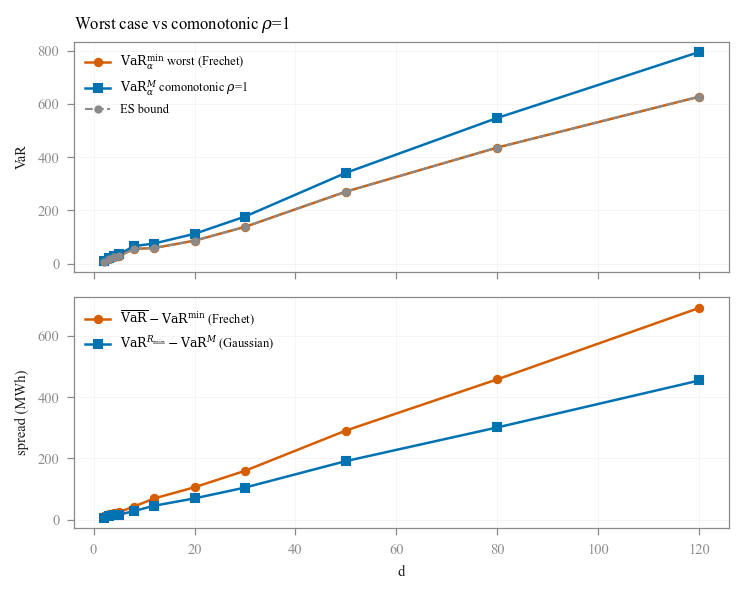

In [19]:
fs = 7
fig, ax = plt.subplots(2, 1, figsize = (5, 4), sharex = True)

ax[0].fill_between(R['d'], R['w_lo'], R['w_hi'], color = ms.ROLE['frechet'], alpha = 0.25, lw = 0) #RA bracket
ax[0].plot(R['d'], R['w_lo'], 'o-', ms = 3.5, color = ms.ROLE['frechet'], label = r'$\mathrm{VaR}^{\min}_{\alpha}$ worst (Frechet)')
ax[0].plot(R['d'], R['M'], 's-', ms = 3.5, color = ms.ROLE['comon'], label = r'$\mathrm{VaR}^{M}_{\alpha}$ comonotonic $\rho$=1')
ax[0].plot(R['d'], R['es'], '.--', lw = 1, color = ms.MUTED, label = 'ES bound')

ax[1].plot(R['d'], R['b_lo'] - R['w_hi'], 'o-', ms = 3.5, color = ms.ROLE['frechet'],
           label = r'$\overline{\mathrm{VaR}} - \mathrm{VaR}^{\min}$ (Frechet)')
ax[1].plot(R['d'], R['Rmin'] - R['M'], 's-', ms = 3.5, color = ms.ROLE['comon'],
           label = r'$\mathrm{VaR}^{R_{\min}} - \mathrm{VaR}^{M}$ (Gaussian)')

ms.style_axes(ax[0], ylabel = 'VaR', title = r'Worst case vs comonotonic $\rho$=1', box = True, grid = 'both', fontsize = fs)
ms.style_axes(ax[1], xlabel = 'd', ylabel = 'spread (MWh)', box = True, grid = 'both', fontsize = fs)
for a in ax: a.legend(fontsize = fs - 1, frameon = False)
fig.tight_layout()


In [13]:
FIGW, FIGH = ms.FIG_COL
C_FRECHET, C_COMON, C_INDEP, C_RHO = (ms.ROLE[k] for k in ('frechet', 'comon', 'indep', 'rho'))
C_INK, C_MUTED = ms.INK, ms.MUTED

ALPHA = 0.90
EPS   = 1 - ALPHA
Z_E   = norm.ppf(EPS)              # -1.2816
PHI_E = norm.pdf(Z_E)              #  0.1755
K_VAR = abs(Z_E)                   #  1.2816  single-asset VaR multiplier
K_ES  = PHI_E / EPS                #  1.7550  single-asset ES  multiplier
K_BST = -PHI_E / (1 - EPS)         # -0.1950  best-case multiplier
DELTA_INF = K_ES / K_VAR           #  1.3694

def arr(R, k): return np.asarray(R[k], dtype=float)
def sum_v(R):  return (arr(R, "mu_Z") - arr(R, "M")) / K_VAR


(0.95, 1.45)

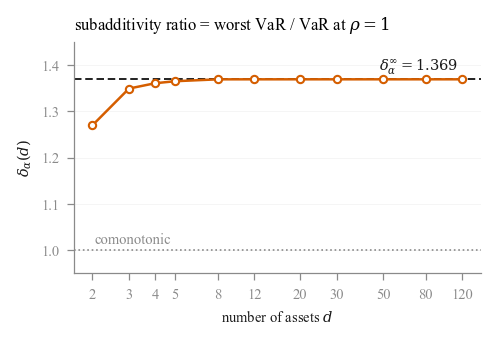

In [27]:
d  = arr(R,"d"); 
mu = arr(R,"mu_Z"); 
base = mu - arr(R,"M")
dlo = (mu - arr(R,"w_hi"))/base          # w_hi -> smaller delta
dhi = (mu - arr(R,"w_lo"))/base
dmid = 0.5*(dlo+dhi)

fig, ax = plt.subplots(figsize=(FIGW, FIGH))
ax.axhline(DELTA_INF, color=C_INK, ls=(0,(4,2)), lw=0.9)
ax.annotate(rf"$\delta_\alpha^\infty={DELTA_INF:.3f}$", xy=(d[-1], DELTA_INF),
            xytext=(-2,4), textcoords="offset points", ha="right", fontsize=7, color=C_INK)
ax.axhline(1.0, color=C_MUTED, ls=":", lw=0.8)
ax.annotate("comonotonic", xy=(d[0], 1.0), xytext=(1,3),
            textcoords="offset points", fontsize=7, color=C_MUTED)
ax.fill_between(d, dlo, dhi, color=C_FRECHET, alpha=0.25, lw=0)   # RA bracket
ax.plot(d, dmid, color=C_FRECHET, marker="o", ms=3.5, mfc="white", mew=1.0, zorder=3)
ax.set_xscale("log"); ax.set_xticks(d)
ax.xaxis.set_major_formatter(mpl.ticker.ScalarFormatter()); ax.minorticks_off()
ms.style_axes(ax, xlabel = r"number of assets $d$", ylabel = r"$\delta_\alpha(d)$",
              title = r"subadditivity ratio = worst VaR / VaR at $\rho=1$", fontsize=fs)
ax.set_ylim(0.95, 1.45)
 

(-0.38, 2.0)

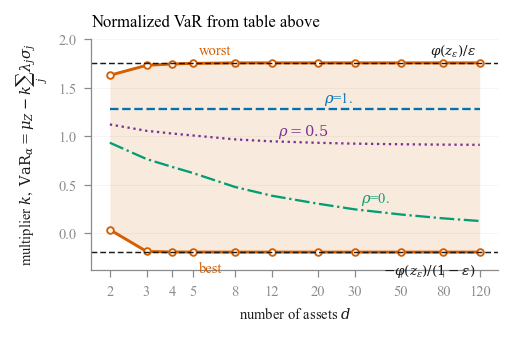

In [29]:
d = arr(R,"d"); mu = arr(R,"mu_Z"); sv = sum_v(R)
k = lambda key: (mu - arr(R,key))/sv

fig, ax = plt.subplots(figsize=(FIGW, FIGH))
ax.fill_between(d, k("b_lo"), k("w_hi"), color=C_FRECHET, alpha=0.13, lw=0)
ax.plot(d, k("w_hi"), color=C_FRECHET, lw=1.4, marker="o", ms=3.2, mfc="white", mew=0.9)
ax.plot(d, k("b_lo"), color=C_FRECHET, lw=1.4, marker="o", ms=3.2, mfc="white", mew=0.9)
ax.plot(d, k("M"),   color=C_COMON, ls="--",        lw=1.1)
ax.plot(d, k("rho"), color=C_RHO,   ls=(0,(1,1.6)), lw=1.1)
ax.plot(d, k("pi"),  color=C_INDEP, ls="-.",        lw=1.1)
for yv, lab in [(K_ES,  r"$\varphi(z_\varepsilon)/\varepsilon$"),
                (K_BST, r"$-\varphi(z_\varepsilon)/(1-\varepsilon)$")]:
    ax.axhline(yv, color=C_INK, ls=(0,(4,2)), lw=0.7)
    ax.annotate(lab, xy=(d[-1], yv), xytext=(-2, 4 if yv>0 else -11),
                textcoords="offset points", ha="right", fontsize=6.5, color=C_INK)
lbl = dict(fontsize=7, textcoords="offset points", ha="left")
ax.annotate("worst",  xy=(d[3], k("w_hi")[3]), xytext=(3,4),   color=C_FRECHET, **lbl)
ax.annotate("best",   xy=(d[3], k("b_lo")[3]), xytext=(3,-10), color=C_FRECHET, **lbl)
ax.annotate(r"$\rho$=1.", xy=(d[6], k("M")[6]),    xytext=(3,3),   color=C_COMON,   **lbl)
ax.annotate(r"$\rho=0.5$", xy=(d[5], k("rho")[5]), xytext=(3,3), color=C_RHO,   **lbl)
ax.annotate(r"$\rho$=0.", xy=(d[7], k("pi")[7]),   xytext=(3,3),   color=C_INDEP,   **lbl)
ax.set_xscale("log"); ax.set_xticks(d)
ax.xaxis.set_major_formatter(mpl.ticker.ScalarFormatter()); ax.minorticks_off()
ms.style_axes(ax, xlabel = r"number of assets $d$",
              ylabel = r"multiplier $k$,  $\mathrm{VaR}_\alpha=\mu_Z-k\sum_j\lambda_j\sigma_j$",
              title = r"Normalized VaR from table above", fontsize=fs)
ax.set_ylim(-0.38, 2.00)

(0.5, 0.995)

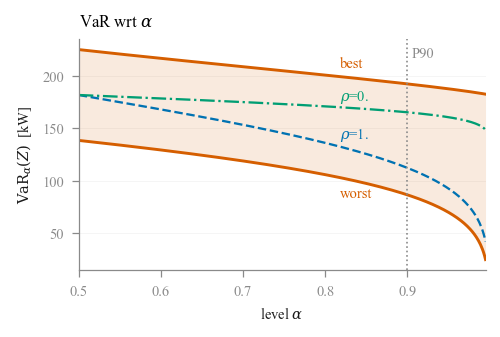

In [30]:
I   = np.where(R["d"] == 20)[0][0] # R["d"].index(20)                      # which d to show
muZ = float(arr(R,"mu_Z")[I]); SV = float(sum_v(R)[I])
L2  = (muZ - float(arr(R,"pi")[I])) / K_VAR        # ||v||_2 from VaR^Pi
RA  = {}                                            # {alpha: (worst, best)}
a   = np.linspace(0.50, 0.995, 400)
ze  = norm.ppf(1-a); ph = norm.pdf(ze)

fig, ax = plt.subplots(figsize=(FIGW, FIGH))
worst = muZ - (ph/(1-a))*SV
best  = muZ + (ph/a)*SV
ax.fill_between(a, worst, best, color=C_FRECHET, alpha=0.13, lw=0)
ax.plot(a, worst, color=C_FRECHET, lw=1.4)
ax.plot(a, best,  color=C_FRECHET, lw=1.4)
ax.plot(a, muZ + ze*SV, color=C_COMON, ls="--", lw=1.1)
ax.plot(a, muZ + ze*L2, color=C_INDEP, ls="-.", lw=1.1)

lbl = dict(fontsize=7, textcoords="offset points", ha="left")
j = 250                                             # alpha ~ 0.81, where curves are separated
ax.annotate("worst", xy=(a[j], worst[j]), xytext=(3,-10), color=C_FRECHET, **lbl)
ax.annotate("best",  xy=(a[j], best[j]),  xytext=(3,4),   color=C_FRECHET, **lbl)
ax.annotate(r"$\rho$=1.", xy=(a[j], muZ + ze[j]*SV), xytext=(3,3), color=C_COMON, **lbl)
ax.annotate(r"$\rho$=0.", xy=(a[j], muZ + ze[j]*L2), xytext=(3,3), color=C_INDEP, **lbl)

for al,(w,b) in RA.items():
    ax.plot([al,al],[w,b], color=C_FRECHET, lw=0, marker="_", ms=5, mew=1.2)
ax.axvline(ALPHA, color=C_MUTED, ls=":", lw=0.8)
ax.annotate("P90", xy=(ALPHA, ax.get_ylim()[1]), xytext=(2,-9), textcoords="offset points", fontsize=7, color=C_MUTED)
ms.style_axes(ax, xlabel = r"level $\alpha$", ylabel = r"$\mathrm{VaR}_\alpha(Z)$  [kW]",
              title = r"VaR wrt $\alpha$", fontsize=fs)
ax.set_xlim(0.5, 0.995)